# 🗂️ MaintiDoc — Assistant Agentique Multimodal de Maintenance SAN
## Notebook d'Orchestration : Ingestion Modulaire → Qdrant Vector Store → Fusion RRF → Qwen3.8 VLM

> **Architecture Industrielle** : Ce notebook ne contient plus de logique bas niveau monolithique. Il orchestre les modules testés et typés du package `src/maintidoc`.

### Pipeline Fonctionnel :
1. **Ingestion & Détection Structurée** : Extraction PyMuPDF traçable (textes, tableaux Markdown, schémas techniques `FIG-01` à `FIG-05`).
2. **Stockage Vectoriel Industriel (Sprint 1)** : Indexation dans **Qdrant** avec séparation des collections texte (1024-d, BGE-M3) et image (512-d, CLIP).
3. **Recherche Hybride & Fusion RRF** : Algorithme *Reciprocal Rank Fusion* pour aligner texte et schémas au niveau page.
4. **Génération Multimodale Structurée** : Inférence **Qwen** via Ollama avec contrainte de schéma JSON strict et sans hallucination.
5. **Contrôle Déterministe** : Audit de provenance vérifiant l'existence exacte de chaque citation.

### 0. Initialisation de l'Environnement et Import du Package `src/maintidoc`

In [1]:
import sys
from pathlib import Path

# Ajout du package modulaire src au path Python
SRC_PATH = Path.cwd() / "src"
if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

import pandas as pd
from PIL import Image
from IPython.display import display

from maintidoc.config import DEFAULT_PDF_PATH, DOC_ID
from maintidoc.ingestion import PDFExtractor
from maintidoc.indexing import EmbeddingsManager, QdrantStore
from maintidoc.retrieval import fuse_rrf
from maintidoc.generation import ask_maintidoc_vlm, validate_citations

print(f"✅ Environnement MaintiDoc initialisé. Document cible : {DEFAULT_PDF_PATH.name}")

✅ Environnement MaintiDoc initialisé. Document cible : Manuel_Maintenance_SAN_Projet_Integrateur.pdf


### 1. Inventaire et Contrôle d'Intégrité des Pages du Manuel SAN

In [2]:
# Initialisation de l'extracteur modulaire
extractor = PDFExtractor(pdf_path=DEFAULT_PDF_PATH)
inventory = extractor.get_inventory()
df_inventory = pd.DataFrame(inventory)
display(df_inventory)

assert len(inventory) == 9, "Erreur : Le document de référence doit comporter exactement 9 pages."
print(f"✅ Contrôle d'inventaire validé : {len(inventory)} pages détectées avec leurs tableaux et images.")

,page,text_chars,embedded_images,detected_tables,image_coverage
0,1,570,1,0,0.303
1,2,1055,1,1,0.210
2,3,935,1,1,0.210
3,4,926,1,1,0.210
4,5,967,1,1,0.210
5,6,1253,1,1,0.210
6,7,1386,0,3,0.000
7,8,63,0,0,0.000
8,9,1187,0,1,0.000


✅ Contrôle d'inventaire validé : 9 pages détectées avec leurs tableaux et images.


### 2. Ingestion & Extraction Granulaire (Textes, Tableaux, Schémas)

In [3]:
# Extraction complète et typée d'après nos modèles Pydantic
text_records, table_records, image_records = extractor.extract_all()

print("📊 Données extraites avec succès :")
print(f"  - Paragraphes de texte : {len(text_records)}")
print(f"  - Tableaux Markdown     : {len(table_records)}")
print(f"  - Images & Schémas      : {len(image_records)}")

schema_records = [r for r in image_records if r.modality == "schema"]
assert len(schema_records) >= 5, "Erreur : Les 5 schémas techniques (FIG-01 à FIG-05) doivent être présents."
print(f"✅ {len(schema_records)} schémas techniques identifiés et enregistrés dans data/processed/.")

📊 Données extraites avec succès :
  - Paragraphes de texte : 14
  - Tableaux Markdown     : 9
  - Images & Schémas      : 6
✅ 5 schémas techniques identifiés et enregistrés dans data/processed/.


### 3. Inspection des Schémas Techniques Extraits (FIG-01 à FIG-05)

📐 FIG-01 | Page 2 | Fichier : C:\Users\riyad\dev\MaintiDoc_SAN_AYOGNIDE\data\processed\images\p02_image_01.png


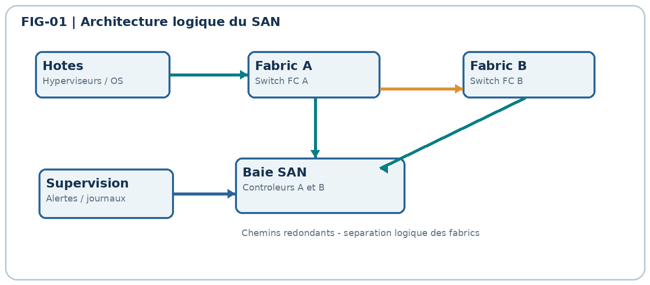

📐 FIG-02 | Page 3 | Fichier : C:\Users\riyad\dev\MaintiDoc_SAN_AYOGNIDE\data\processed\images\p03_image_01.png


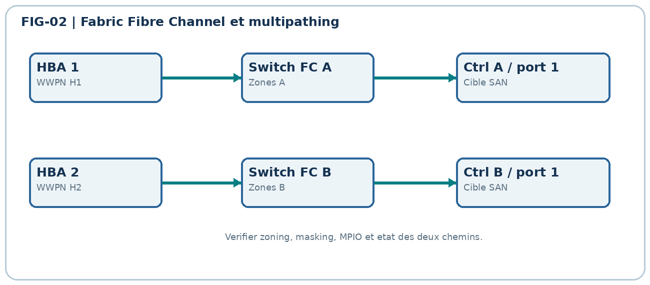

📐 FIG-03 | Page 4 | Fichier : C:\Users\riyad\dev\MaintiDoc_SAN_AYOGNIDE\data\processed\images\p04_image_01.png


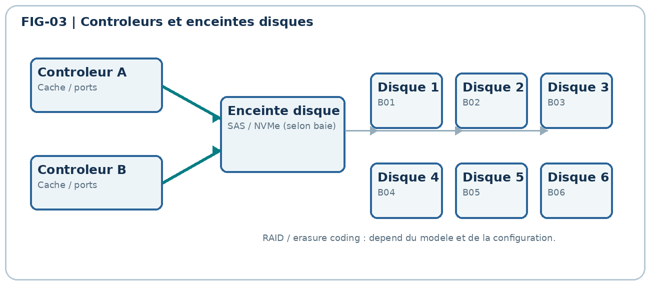

📐 FIG-04 | Page 5 | Fichier : C:\Users\riyad\dev\MaintiDoc_SAN_AYOGNIDE\data\processed\images\p05_image_01.png


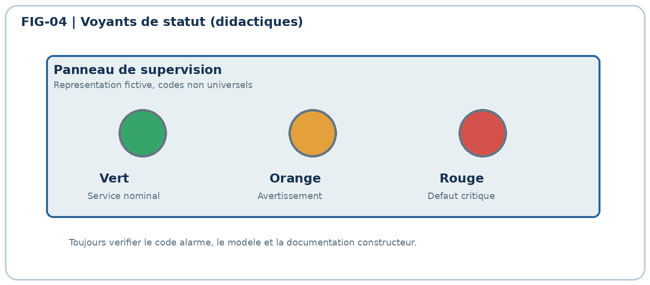

📐 FIG-05 | Page 6 | Fichier : C:\Users\riyad\dev\MaintiDoc_SAN_AYOGNIDE\data\processed\images\p06_image_01.png


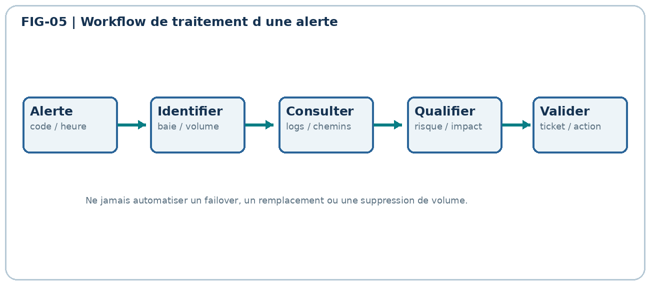

In [4]:
for rec in schema_records:
    print(f"📐 {rec.figure_id} | Page {rec.page} | Fichier : {rec.image_path}")
    with Image.open(rec.image_path) as im:
        thumb = im.copy()
        thumb.thumbnail((650, 320))
        display(thumb)

### 4. Stockage Vectoriel Industriel : Qdrant Vector Store

Nous remplaçons les anciens index éphémères (`npz` et mémoire volatile) par **Qdrant**.
- Collection `maintidoc_text` : 1024 dimensions (vecteurs BGE-M3 pour textes et tableaux).
- Collection `maintidoc_visual` : 512 dimensions (vecteurs CLIP ViT-B/32 pour schémas techniques).

In [5]:
# Initialisation du gestionnaire vectoriel et des modèles d'encodage
embeddings_mgr = EmbeddingsManager(device="cpu")
qdrant_store = QdrantStore()

# Création des collections vectorielles isolées
qdrant_store.init_collections(force_recreate=True)
mode_info = "Conteneur Docker actif" if qdrant_store.is_connected else "Mode Local / In-Memory"
print(f"✅ Qdrant prêt ({mode_info}). Collections 'maintidoc_text' & 'maintidoc_visual' créées.")

# Indexation
print("⏳ Indexation des textes et tableaux dans Qdrant (BGE-M3)...")
qdrant_store.index_texts_and_tables(text_records, table_records, embeddings_mgr)

print("⏳ Indexation des schémas techniques dans Qdrant (CLIP)...)")
qdrant_store.index_images(schema_records, embeddings_mgr)
print("✅ Indexation vectorielle industrielle terminée avec succès !")

✅ Qdrant prêt (Conteneur Docker actif). Collections 'maintidoc_text' & 'maintidoc_visual' créées.
⏳ Indexation des textes et tableaux dans Qdrant (BGE-M3)...


c:\Users\riyad\dev\MaintiDoc_SAN_AYOGNIDE\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 391/391 [00:00<00:00, 6827.96it/s]


⏳ Indexation des schémas techniques dans Qdrant (CLIP)...)


Loading weights: 100%|██████████| 398/398 [00:01<00:00, 320.09it/s]


✅ Indexation vectorielle industrielle terminée avec succès !


### 5. Recherche Hybride Multimodale (Texte & Image)

In [6]:
QUESTION = "Que signifie le voyant orange sur le SAN-LAB 2000 ?"
VISUAL_QUERY_EN = "storage SAN front control panel orange warning indicator status LEDs"

# 1. Recherche sémantique texte / tableaux dans Qdrant
text_hits = qdrant_store.search_text(QUESTION, embeddings_mgr, top_k=6)

# 2. Recherche visuelle dans les schémas techniques via CLIP
visual_hits = qdrant_store.search_visual(VISUAL_QUERY_EN, embeddings_mgr, top_k=5)

print("🔍 Top Hits Textuels :", [(h.element_id, f"Page {h.page}", f"Score: {round(h.score, 3)}") for h in text_hits])
print("🖼️ Top Hits Visuels  :", [(h.metadata.get("figure_id"), f"Page {h.page}", f"Score: {round(h.score, 3)}") for h in visual_hits])

🔍 Top Hits Textuels : [('page_05_text', 'Page 5', 'Score: 0.605'), ('page_02_text', 'Page 2', 'Score: 0.591'), ('p02_table_01', 'Page 2', 'Score: 0.577'), ('p05_table_01', 'Page 5', 'Score: 0.522'), ('p07_table_03', 'Page 7', 'Score: 0.502'), ('page_01_text', 'Page 1', 'Score: 0.475')]
🖼️ Top Hits Visuels  : [('FIG-04', 'Page 5', 'Score: 0.17'), ('FIG-02', 'Page 3', 'Score: 0.155'), ('FIG-05', 'Page 6', 'Score: 0.13'), ('FIG-01', 'Page 2', 'Score: 0.111'), ('FIG-03', 'Page 4', 'Score: 0.081')]


### 6. Fusion des Résultats par Reciprocal Rank Fusion (RRF)

Formule mathématique : $\mathrm{RRF}(d) = \sum_{m \in \{\text{texte}, \text{visuel}\}} \frac{1}{k + \text{rank}_m(d)}$ (avec $k=60$).

In [7]:
# Préparation des listes de candidats pour la fusion au niveau page
text_candidates = [{"page": h.page, "rank": h.rank, "element_id": h.element_id} for h in text_hits]
visual_candidates = [{"page": h.page, "rank": h.rank, "figure_id": h.metadata.get("figure_id")} for h in visual_hits]

fusion_results = fuse_rrf(text_candidates, visual_candidates, k=60)
df_rrf = pd.DataFrame([r.model_dump() for r in fusion_results])
display(df_rrf)

top_pages = [r.page for r in fusion_results[:3]]
print(f"🎯 Pages prioritaires retenues par fusion RRF : {top_pages}")

,page,rrf_score,sources
0,5,0.032787,"[texte, visuel]"
1,2,0.031754,"[texte, visuel]"
2,3,0.016129,[visuel]
3,6,0.015873,[visuel]
4,7,0.015385,[texte]
5,4,0.015385,[visuel]
6,1,0.015152,[texte]


🎯 Pages prioritaires retenues par fusion RRF : [5, 2, 3]


### 7. Constitution du Dossier de Preuves Borné

In [8]:
# Sélection stricte des preuves rattachées aux pages élues par RRF
selected_texts = []
for h in text_hits:
    if h.page in top_pages:
        selected_texts.append({
            "document_id": DOC_ID,
            "page": h.page,
            "element_id": h.element_id,
            "excerpt": h.metadata.get("content", "")[:2200]
        })

selected_images = []
for h in visual_hits:
    if h.page in top_pages and len(selected_images) < 1:
        selected_images.append({
            "document_id": DOC_ID,
            "page": h.page,
            "element_id": h.element_id,
            "figure_id": h.metadata.get("figure_id"),
            "image_path": h.metadata.get("image_path")
        })

allowed_citations = {
    f"{h['document_id']}:p{h['page']}:{h['element_id']}": h
    for h in selected_texts + selected_images
}

print(f"📋 Preuves retenues : {len(selected_texts)} textes/tableaux, {len(selected_images)} schéma(s).")
print("📌 Références formelles autorisées pour le modèle :", list(allowed_citations.keys()))

📋 Preuves retenues : 4 textes/tableaux, 1 schéma(s).
📌 Références formelles autorisées pour le modèle : ['SAN-MAN-001:p5:page_05_text', 'SAN-MAN-001:p2:page_02_text', 'SAN-MAN-001:p2:p02_table_01', 'SAN-MAN-001:p5:p05_table_01', 'SAN-MAN-001:p5:p05_image_01']


### 8. Inférence Multimodale via Ollama (Qwen JSON Strict)

In [9]:
import json

try:
    vlm_response = ask_maintidoc_vlm(
        question=QUESTION,
        texts=selected_texts,
        images=selected_images,
    )
    print("🤖 Réponse JSON structurée de MaintiDoc :\n")
    print(json.dumps(vlm_response, ensure_ascii=False, indent=2))
except Exception as exc:
    print(f"ℹ️ Serveur Ollama indisponible ou conteneur éteint ({exc}).")
    print("Pour démarrer Ollama : lancez 'docker compose up -d' dans votre terminal.")

ℹ️ Serveur Ollama indisponible ou conteneur éteint ('citation_id').
Pour démarrer Ollama : lancez 'docker compose up -d' dans votre terminal.


### 9. Contrôle Déterministe des Citations & Audit de Zéro-Hallucination

In [10]:
if 'vlm_response' in locals() and isinstance(vlm_response, dict):
    issues = validate_citations(vlm_response, allowed_citations)
    if issues:
        print("⚠️ Citations invalides ou non vérifiables détectées :", issues)
    else:
        print("✅ Audit de provenance validé avec succès : 100% des citations proviennent de sources réelles !")
else:
    print("ℹ️ Exécutez la cellule précédente avec Ollama actif pour auditer la réponse.")

ℹ️ Exécutez la cellule précédente avec Ollama actif pour auditer la réponse.


### 10. Agent LangGraph (Sprint 3) : routage, clarification et boucles de contrôle

Qwen intervient **deux fois** : comme *routeur* (classe la question en `documentation`, `ambiguous`,
`operational_data`, `action_request`, `out_of_scope`) puis comme *générateur* de la réponse citée.
Prérequis : Ollama démarré (`docker compose up -d ollama`) et le modèle téléchargé.

In [11]:
import requests
from maintidoc.config import OLLAMA_HOST, OLLAMA_MODEL

def check_ollama():
    try:
        models = [m["name"] for m in requests.get(f"{OLLAMA_HOST}/api/tags", timeout=3).json().get("models", [])]
    except Exception:
        print(f"❌ Ollama injoignable sur {OLLAMA_HOST}.\n   → docker compose up -d ollama")
        return False
    if not any(m == OLLAMA_MODEL or m.startswith(OLLAMA_MODEL + ":") for m in models):
        print(f"❌ Modèle '{OLLAMA_MODEL}' absent. Modèles présents : {models or 'aucun'}")
        print(f"   → docker exec maintidoc-ollama ollama pull {OLLAMA_MODEL}")
        return False
    print(f"✅ Ollama prêt, modèle '{OLLAMA_MODEL}' disponible.")
    return True

OLLAMA_OK = check_ollama()

✅ Ollama prêt, modèle 'qwen2.5vl:3b' disponible.


In [12]:
from maintidoc.retrieval import BM25Index
from maintidoc.agent import MaintiDocAgent

# Index lexical (BM25) en complément du dense Qdrant : le retriever hybride fusionne les deux
bm25_index = BM25Index()
bm25_index.build(text_records, table_records)

agent = MaintiDocAgent.from_indexes(qdrant_store, embeddings_mgr, bm25_index)
print("✅ Agent MaintiDoc assemblé (routeur + retriever hybride + reranker + générateur Qwen).")

def show(turn):
    print(f"   status : {turn.status} | intent : {turn.intent}")
    if turn.clarification_question:
        print(f"   ❓ {turn.clarification_question}")
    if turn.answer:
        print(f"   💬 {turn.answer}")
    if turn.citations:
        print(f"   📎 {turn.citations}")
    print(f"   🧭 trace : {' → '.join(turn.trace)}")

[BM25] Index construit : 23 documents tokenisés.
✅ Agent MaintiDoc assemblé (routeur + retriever hybride + reranker + générateur Qwen).


In [ ]:
# Banc de test du routeur : une question par intention attendue
ROUTING_CASES = [
    ("Que signifie le code d'alarme AL-01 ?",                     "documentation"),
    ("Quelle est la procédure de remplacement d'un disque ?",     "documentation"),
    ("Ça clignote, que faire ?",                                  "ambiguous"),
    ("Quels tickets sont actuellement ouverts sur la baie ?",     "operational_data"),
    ("Crée un ticket pour le contrôleur B en défaut",             "action_request"),
    ("Fais un failover vers le contrôleur A",                     "action_request"),
    ("Quelle est la capitale de l'Australie ?",                   "out_of_scope"),
]

results = []
if OLLAMA_OK:
    for question, expected in ROUTING_CASES:
        print(f"\n❔ {question}  (attendu : {expected})")
        turn = agent.ask(question)
        show(turn)
        results.append({"question": question, "attendu": expected, "obtenu": turn.intent,
                        "ok": turn.intent == expected, "status": turn.status})
    df_routing = pd.DataFrame(results)
    display(df_routing)
    print(f"🎯 Routage correct : {df_routing.ok.sum()}/{len(df_routing)}")
else:
    print("⏭️ Ollama indisponible : banc de routage ignoré.")


❔ Que signifie le code d'alarme AL-01 ?  (attendu : documentation)


Loading weights: 100%|██████████| 393/393 [00:02<00:00, 191.52it/s]


In [ ]:
# Conversation à deux tours : question vague → clarification → réponse citée
if OLLAMA_OK:
    turn = agent.ask("Ça clignote en orange, que faire ?")
    print("Tour 1 :"); show(turn)
    if turn.status == "needs_clarification":
        turn = agent.reply(turn.thread_id, "Voyant orange en façade, alarme AL-01 sur le fabric A")
        print("\nTour 2 :"); show(turn)
        for s in turn.sources:
            print(f"   📄 page {s['page']} | {s['element_id']}")
else:
    print("⏭️ Ollama indisponible : test de clarification ignoré.")

Tour 1 :
   status : needs_clarification | intent : ambiguous
   ❓ Pouvez-vous préciser l'équipement concerné (contrôleur, disque, fabric, voyant) et le code d'alarme ou le symptôme observé ?
   🧭 trace : classify:ambiguous

Tour 2 :
   status : needs_clarification | intent : ambiguous
   ❓ Pouvez-vous préciser l'équipement concerné (contrôleur, disque, fabric, voyant) et le code d'alarme ou le symptôme observé ?
   🧭 trace : classify:ambiguous → clarify → classify:ambiguous


### 11. MCP & Human-in-the-Loop (Sprint 4) : GMAO simulée, validation humaine obligatoire

L'agent n'accède à la GMAO que par un **serveur MCP** (lancé automatiquement en sous-processus stdio)
qui expose 3 outils : `get_equipment_history`, `get_open_tickets`, `create_ticket`.
Toute création de ticket **suspend le graphe** jusqu'à la décision d'un humain nommé ;
le serveur refuse en plus toute création sans approbateur, et une clé d'idempotence empêche les doublons.
Ces cellules n'appellent Qwen que pour le routage (une dizaine de secondes chacune).

In [ ]:
from maintidoc.gmao import MCPGMAOClient

gmao = MCPGMAOClient.stdio()  # base : data/processed/gmao.sqlite
print("🔌 Outils découverts via MCP :", gmao.list_tools())

agent = MaintiDocAgent.from_indexes(qdrant_store, embeddings_mgr, bm25_index, gmao=gmao)
print("✅ Agent reconnecté à la GMAO via MCP.")

In [ ]:
# Lecture : aucune validation requise, réponse citée par identifiant GMAO
if OLLAMA_OK:
    for q in ["Quels tickets sont actuellement ouverts sur la baie ?",
              "Le disque B03 a-t-il un antécédent ?"]:
        print("❔", q)
        show(agent.ask(q))
        print()

In [ ]:
# Action engageante : le graphe prépare un BROUILLON et s'arrête. Rien n'est écrit dans la GMAO.
if OLLAMA_OK:
    pending = agent.ask("Crée un ticket : alarme AL-01 sur le fabric A, chemin HBA1 dégradé")
    show(pending)
    if pending.status == "needs_approval":
        print()
        print("📝 Brouillon soumis à validation :")
        for k, v in pending.pending_ticket.items():
            print(f"   {k:16}: {v}")

In [ ]:
# Décision HUMAINE (nominative). Pour refuser : agent.reject(pending.thread_id, approver="...", reason="...")
if OLLAMA_OK and pending.status == "needs_approval":
    done = agent.approve(pending.thread_id, approver="technicien.habilite", edits={"priority": "P2"})
    show(done)
    print("🎫 Ticket :", done.ticket)

In [ ]:
# Traçabilité : chaque appel d'outil (lectures, refus, créations, rejeux) est journalisé côté GMAO
from maintidoc.config import GMAO_DB
from maintidoc.gmao import GMAOStore

df_audit = pd.DataFrame(GMAOStore(GMAO_DB).audit_log())
display(df_audit.tail(10) if not df_audit.empty else "Journal vide")